
# Does Restaurant Food Safety Vary Across NYC Boroughs?

## Project 3 Prompt

- **Dataset(s) to be used:** [NYC Restaurant Inspection Results](https://data.cityofnewyork.us/Health/DOHMH-New-York-City-Restaurant-Inspection-Results/43nn-pn8j)

- **Analysis question:** Does the proportion of NYC restaurants receiving an A grade differ across boroughs?

- **Columns that will (likely) be used:**
  - `camis` — Restaurant identifier
  - `boro` — Borough
  - `cuisine_description` — Cuisine category
  - `inspection_date` — Inspection date
  - `inspection_type` — Type of inspection
  - `grade` — Inspection grade
  - `score` — Inspection score

- **Columns to be used to merge/join datasets:** Not applicable; this project uses one dataset.

- **Hypothesis:** The proportion of restaurants receiving an A grade differs across NYC boroughs. I expect to find variation, although cuisine type and inspection characteristics may help explain some of the differences.


## Introduction

Restaurant health inspections are an important part of protecting public health. In New York City, restaurants are inspected by the Department of Health and assigned grades based on their inspection results.

I want to explore whether restaurant food safety outcomes differ across NYC's five boroughs. Specifically, I'll compare the proportion of restaurants receiving an A grade and investigate whether cuisine type helps explain any differences.

## Loading and Exploring the Data

I'll begin by loading restaurant inspection records from NYC Open Data and examining the dataset's structure.

Before analyzing inspection grades, I also need to understand how the data are organized, since individual restaurants may have multiple inspections and each inspection can contain multiple violation records.

In [27]:
import os
import certifi
import requests
import pandas as pd
import matplotlib.pyplot as plt

# Use trusted certificates for HTTPS connections
os.environ["SSL_CERT_FILE"] = certifi.where()


# Load the first 1,000 restaurant inspection records
url = "https://data.cityofnewyork.us/resource/43nn-pn8j.csv"

restaurants = pd.read_csv(url, nrows=1000)

restaurants.head()

,camis,dba,boro,building,street,zipcode,phone,cuisine_description,inspection_date,action,...,inspection_type,latitude,longitude,community_board,council_district,census_tract,bin,bbl,nta,location
0,50188691,98k chicken&burger,Brooklyn,5424,7 AVENUE,11220.0,3472008168,NaN,1900-01-01T00:00:00.000,NaN,...,NaN,40.640021,-74.008439,307.0,43.0,10000.0,3014759.0,3.008250e+09,BK34,POINT (-74.008438705664 40.640021281042)
1,50162192,MESSY,Manhattan,149,SULLIVAN STREET,10012.0,6466840808,NaN,1900-01-01T00:00:00.000,NaN,...,NaN,40.727086,-74.001844,102.0,3.0,4900.0,1008045.0,1.005170e+09,MN24,POINT (-74.001843652469 40.727085821019)
2,50105063,FINNEGAN'S WAKE,Manhattan,1361,1 AVENUE,10021.0,6465266083,Irish,2025-08-04T00:00:00.000,No violations were recorded at the time of thi...,...,Administrative Miscellaneous / Initial Inspection,40.768578,-73.955439,108.0,5.0,12600.0,1044905.0,1.014480e+09,MN31,POINT (-73.955439460636 40.768577977001)
3,50193640,MONTI'S TAVERN LLC,Queens,584,SENECA AVENUE,11385.0,9174998116,NaN,1900-01-01T00:00:00.000,NaN,...,NaN,40.704374,-73.910363,405.0,34.0,54700.0,4082174.0,4.034400e+09,QN20,POINT (-73.910362756145 40.70437352227)
4,50114783,"HUDSON NIA JFK T1, JV",Queens,JFK,TERMINAL 1,11430.0,201 8218189,NaN,1900-01-01T00:00:00.000,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



### Initial Data Exploration

The dataset contains information about NYC restaurants and their health inspections. However, not every row represents a completed inspection. Some records have missing grades, and some dates appear to be placeholders.

I'll examine the columns, missing values, and distribution of restaurants across boroughs before deciding how to clean the data.

In [28]:
# Check dataset size and columns
print("Dataset shape:", restaurants.shape)

print("\nColumn names:")
print(restaurants.columns.tolist())

# Check missing values in important columns
columns_to_check = [
    "camis",
    "boro",
    "cuisine_description",
    "inspection_date",
    "inspection_type",
    "grade",
    "score",
]

print("\nMissing values:")
print(restaurants[columns_to_check].isna().sum())

# Count records by borough
print("\nRecords by borough:")
print(restaurants["boro"].value_counts())

Dataset shape: (1000, 27)

Column names:
['camis', 'dba', 'boro', 'building', 'street', 'zipcode', 'phone', 'cuisine_description', 'inspection_date', 'action', 'violation_code', 'violation_description', 'critical_flag', 'score', 'grade', 'grade_date', 'record_date', 'inspection_type', 'latitude', 'longitude', 'community_board', 'council_district', 'census_tract', 'bin', 'bbl', 'nta', 'location']

Missing values:
camis                    0
boro                     0
cuisine_description    786
inspection_date          0
inspection_type        786
grade                  914
score                  812
dtype: int64

Records by borough:
boro
Manhattan        438
Brooklyn         245
Queens           195
Bronx             52
0                 43
Staten Island     27
Name: count, dtype: int64



### Selecting Relevant Inspection Records

The initial sample contains many missing grades, so it is not suitable for comparing restaurant grades across boroughs.

I'll retrieve a larger set of graded inspection records from 2024 onward. I'll focus on grades A, B, and C and exclude records without a valid NYC borough.

Later, I'll account for restaurants appearing multiple times so that repeated violation records do not distort the results.

In [29]:
from io import StringIO

# Request recent graded inspection records
api_url = "https://data.cityofnewyork.us/resource/43nn-pn8j.csv"

params = {
    "$select": (
        "camis,boro,cuisine_description,inspection_date,inspection_type,grade,score"
    ),
    "$where": ("grade in('A','B','C') AND inspection_date >= '2024-01-01'"),
    "$order": "inspection_date DESC, camis",
    "$limit": 5000,
}

response = requests.get(api_url, params=params, verify=certifi.where(), timeout=60)
response.raise_for_status()

graded_sample = pd.read_csv(StringIO(response.text))

print("Records retrieved:", len(graded_sample))
print("\nGrade counts:")
print(graded_sample["grade"].value_counts())

graded_sample.head()

Records retrieved: 5000

Grade counts:
grade
A    4686
B     173
C     141
Name: count, dtype: int64


,camis,boro,cuisine_description,inspection_date,inspection_type,grade,score
0,40365577,Manhattan,Italian,2026-11-17T00:00:00.000,Cycle Inspection / Initial Inspection,A,12
1,40365577,Manhattan,Italian,2026-11-17T00:00:00.000,Cycle Inspection / Initial Inspection,A,12
2,40365577,Manhattan,Italian,2026-11-17T00:00:00.000,Cycle Inspection / Initial Inspection,A,12
3,40380432,Manhattan,American,2026-11-17T00:00:00.000,Cycle Inspection / Initial Inspection,A,9
4,40380432,Manhattan,American,2026-11-17T00:00:00.000,Cycle Inspection / Initial Inspection,A,9


### Retrieving the Full Analysis Dataset

The first 5,000 graded records contain repeated entries for the same restaurants and inspections. They also represent only the most recent records, which could bias the comparison across boroughs.

To make the analysis more representative, I'll retrieve all available A, B, and C inspection records from 2024 onward in batches. Afterward, I'll remove duplicate inspection records and select the latest qualifying inspection for each restaurant.

In [30]:
# Retrieve all qualifying inspection records in batches
all_batches = []
batch_size = 50000
offset = 0

while True:
    params["$limit"] = batch_size
    params["$offset"] = offset

    response = requests.get(api_url, params=params, verify=certifi.where(), timeout=120)
    response.raise_for_status()

    batch = pd.read_csv(StringIO(response.text))

    if batch.empty:
        break

    all_batches.append(batch)
    print(f"Retrieved {offset + len(batch):,} records")

    if len(batch) < batch_size:
        break

    offset += batch_size

# Combine all batches into one DataFrame
full_restaurants = pd.concat(all_batches, ignore_index=True)

print(f"\nTotal records retrieved: {len(full_restaurants):,}")
print(f"Unique restaurants: {full_restaurants['camis'].nunique():,}")

Retrieved 50,000 records
Retrieved 100,000 records
Retrieved 108,226 records

Total records retrieved: 108,226
Unique restaurants: 24,284


## Cleaning the Inspection Data

The full dataset contains over 108,000 records, but many represent multiple violations from the same inspection.

To avoid counting the same inspection multiple times, I'll first remove duplicate inspection records. Then I'll select the latest graded inspection for each restaurant.

I'll also remove invalid borough values and missing restaurant identifiers. This will give me a cleaner dataset for comparing A-grade proportions across NYC's five boroughs.

In [31]:
# Create a copy of the full dataset
clean_df = full_restaurants.copy()

# Convert inspection dates to datetime
clean_df["inspection_date"] = pd.to_datetime(
    clean_df["inspection_date"], errors="coerce"
)

# Keep only the five NYC boroughs
valid_boroughs = ["Manhattan", "Brooklyn", "Queens", "Bronx", "Staten Island"]

clean_df = clean_df[clean_df["boro"].isin(valid_boroughs)].copy()

# Remove missing restaurant IDs, dates, and grades
clean_df = clean_df.dropna(subset=["camis", "inspection_date", "grade"])

# Remove repeated records from the same inspection
clean_df = clean_df.drop_duplicates(
    subset=["camis", "inspection_date", "inspection_type", "grade"]
)

# Keep the latest graded inspection for each restaurant
clean_df = clean_df.sort_values(["camis", "inspection_date"], ascending=[True, False])

latest_inspections = clean_df.drop_duplicates(subset=["camis"], keep="first").copy()

print("Unique restaurants analyzed:", len(latest_inspections))

print("\nRestaurants by borough:")
print(latest_inspections["boro"].value_counts())

print("\nGrades:")
print(latest_inspections["grade"].value_counts())

Unique restaurants analyzed: 24263

Restaurants by borough:
boro
Manhattan        9484
Brooklyn         6193
Queens           5544
Bronx            2207
Staten Island     835
Name: count, dtype: int64

Grades:
grade
A    21724
B     1914
C      625
Name: count, dtype: int64


### Checking for Conflicting Inspection Grades

Some restaurants may have multiple inspection records on the same date. Before comparing grades across boroughs, I'll check whether any restaurants have different grades recorded on their most recent inspection date.

This will help ensure that each restaurant is assigned a consistent grade in the final analysis.

In [32]:
# Find each restaurant's most recent inspection date
latest_dates = clean_df.groupby("camis")["inspection_date"].transform("max")

# Keep all records from each restaurant's most recent date
latest_records = clean_df[clean_df["inspection_date"] == latest_dates].copy()

# Count distinct grades on the most recent date
grade_counts = latest_records.groupby("camis")["grade"].nunique()

# Identify restaurants with conflicting grades
conflicting_ids = grade_counts[grade_counts > 1].index

print("Restaurants with conflicting latest grades:", len(conflicting_ids))

# Display examples, if any
conflicting_records = latest_records[latest_records["camis"].isin(conflicting_ids)]

conflicting_records[
    ["camis", "boro", "inspection_date", "inspection_type", "grade"]
].head(10)

Restaurants with conflicting latest grades: 0


,camis,boro,inspection_date,inspection_type,grade


## Comparing Restaurant Grades Across Boroughs

Now that each restaurant has one qualifying graded inspection record, I'll calculate the percentage receiving an A grade in each borough.

Comparing percentages rather than raw counts is important because the number of restaurants differs substantially across boroughs.

This will allow me to see whether A-grade proportions vary geographically, as predicted by my hypothesis.

In [33]:
# Create an indicator for restaurants receiving an A grade
latest_inspections["is_a"] = (latest_inspections["grade"] == "A").astype(int)

# Group restaurants by borough
borough_summary = (
    latest_inspections.groupby("boro")
    .agg(
        total_restaurants=("camis", "count"),
        a_grades=("is_a", "sum"),
        a_grade_rate=("is_a", "mean"),
    )
    .reset_index()
)

# Convert proportions to percentages
borough_summary["a_grade_pct"] = borough_summary["a_grade_rate"] * 100

# Sort boroughs by A-grade percentage
borough_summary = borough_summary.sort_values("a_grade_pct", ascending=False)

borough_summary

,boro,total_restaurants,a_grades,a_grade_rate,a_grade_pct
2,Manhattan,9484,8620,0.908899,90.889920
4,Staten Island,835,755,0.904192,90.419162
1,Brooklyn,6193,5589,0.902471,90.247053
0,Bronx,2207,1966,0.890802,89.080199
3,Queens,5544,4794,0.864719,86.471861


## Visualizing A-Grade Rates Across Boroughs

The results show some differences in A-grade percentages across NYC's five boroughs. Manhattan has the highest percentage, while Queens has the lowest.

To make these differences easier to compare, I'll create a bar chart showing the percentage of restaurants receiving an A grade in each borough.

This visualization uses percentages rather than raw counts to account for the different numbers of restaurants in each borough.

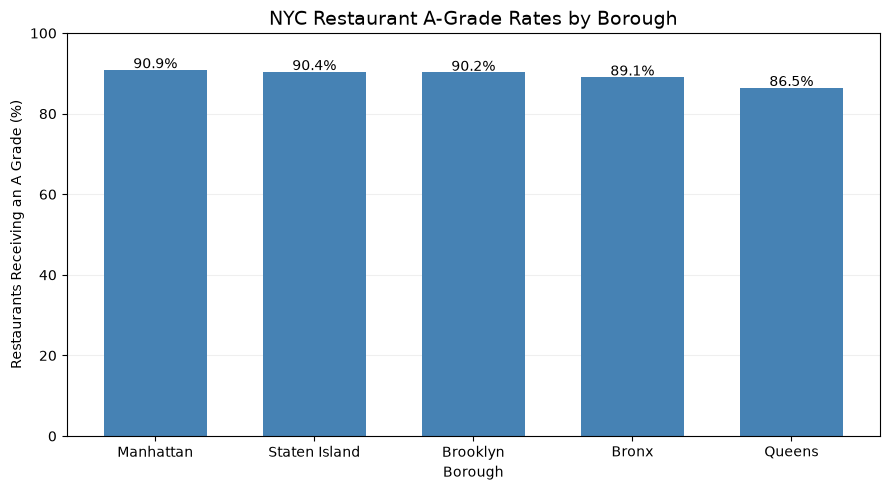

In [34]:
# Visualize A-grade percentages by borough
fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    borough_summary["boro"],
    borough_summary["a_grade_pct"],
    color="steelblue",
    width=0.65,
)

# Add percentage labels above each bar
for bar in bars:
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.4,
        f"{height:.1f}%",
        ha="center",
        fontsize=10,
    )

ax.set_title("NYC Restaurant A-Grade Rates by Borough", fontsize=14)
ax.set_xlabel("Borough")
ax.set_ylabel("Restaurants Receiving an A Grade (%)")

ax.set_ylim(0, 100)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

## Testing the Hypothesis

The chart shows differences in A-grade percentages across boroughs, but I want to determine whether these differences are statistically significant.

I'll use a chi-square test of independence to examine whether receiving an A grade is associated with a restaurant's borough.

The null hypothesis is that A-grade proportions are the same across all five boroughs. The alternative hypothesis is that at least one borough has a different A-grade proportion.

I'll use a significance level of 0.05.

In [35]:
from scipy.stats import chi2_contingency

# Create a table of A grades versus non-A grades by borough
contingency_table = pd.crosstab(latest_inspections["boro"], latest_inspections["is_a"])

contingency_table.columns = ["Not A", "A"]

# Perform chi-square test
chi2, p_value, dof, expected = chi2_contingency(contingency_table)

print("Grade distribution by borough:")
print(contingency_table)

print(f"\nChi-square statistic: {chi2:.3f}")
print(f"P-value: {p_value:.6g}")
print(f"Degrees of freedom: {dof}")

if p_value < 0.05:
    print("\nResult: Reject the null hypothesis.")
    print("A-grade proportions differ significantly across boroughs.")
else:
    print("\nResult: Fail to reject the null hypothesis.")
    print("There is insufficient evidence of differences across boroughs.")

Grade distribution by borough:
               Not A     A
boro                      
Bronx            241  1966
Brooklyn         604  5589
Manhattan        864  8620
Queens           750  4794
Staten Island     80   755

Chi-square statistic: 78.637
P-value: 3.38621e-16
Degrees of freedom: 4

Result: Reject the null hypothesis.
A-grade proportions differ significantly across boroughs.


## Exploring the Role of Cuisine Type

The chi-square test suggests that A-grade proportions differ significantly across boroughs. However, borough location may not be the only factor associated with inspection outcomes.

Different boroughs have different mixes of restaurant cuisine types. I'll examine whether A-grade percentages vary across major cuisine categories and whether those categories are distributed differently across boroughs.

This may help explain some of the geographic variation, although it cannot establish causation.

In [36]:
# Remove restaurants with missing cuisine information
cuisine_df = latest_inspections.dropna(subset=["cuisine_description"]).copy()

# Calculate A-grade rates for each cuisine category
cuisine_summary = (
    cuisine_df.groupby("cuisine_description")
    .agg(
        total_restaurants=("camis", "count"),
        a_grades=("is_a", "sum"),
        a_grade_rate=("is_a", "mean"),
    )
    .reset_index()
)

# Keep cuisine categories with at least 100 restaurants
cuisine_summary = cuisine_summary[cuisine_summary["total_restaurants"] >= 100].copy()

# Convert to percentages
cuisine_summary["a_grade_pct"] = cuisine_summary["a_grade_rate"] * 100

# Sort by A-grade percentage
cuisine_summary = cuisine_summary.sort_values("a_grade_pct", ascending=False)

print("Cuisine categories with at least 100 restaurants:")
print(len(cuisine_summary))

cuisine_summary[["cuisine_description", "total_restaurants", "a_grade_pct"]].round(2)

Cuisine categories with at least 100 restaurants:
36


,cuisine_description,total_restaurants,a_grade_pct
72,Salads,124,99.19
27,Donuts,535,98.13
59,New American,181,96.69
63,Other,341,96.48
39,Hamburgers,474,95.99
22,Coffee/Tea,1986,95.62
85,Tex-Mex,303,95.05
73,Sandwiches,419,94.27
33,French,254,94.09
74,Sandwiches/Salads/Mixed Buffet,148,93.92


### Comparing Cuisine Types Across Boroughs

The results show considerable variation in A-grade percentages across cuisine categories. For example, some categories have A-grade rates above 95%, while others have rates below 80%.

This raises another question: could differences in the mix of cuisines across boroughs help explain the geographic variation in restaurant grades?

To explore this, I'll compare A-grade percentages within cuisine categories across the five boroughs. I'll focus on the ten most common cuisine categories and display the results in a heatmap.

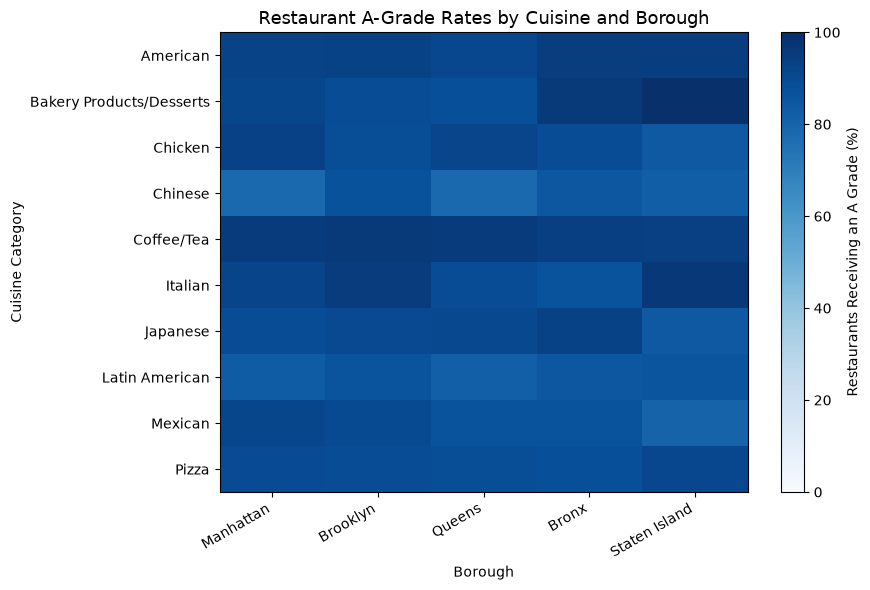

In [37]:
# Identify the ten most common cuisine categories
top_cuisines = cuisine_df["cuisine_description"].value_counts().head(10).index

# Keep restaurants belonging to these categories
top_cuisine_df = cuisine_df[cuisine_df["cuisine_description"].isin(top_cuisines)].copy()

# Calculate A-grade rates by borough and cuisine
borough_cuisine = (
    top_cuisine_df.groupby(["cuisine_description", "boro"])
    .agg(restaurants=("camis", "count"), a_grade_rate=("is_a", "mean"))
    .reset_index()
)

# Reshape data into a table for visualization
cuisine_heatmap = (
    borough_cuisine.pivot(
        index="cuisine_description", columns="boro", values="a_grade_rate"
    )
    * 100
)

# Arrange boroughs consistently
cuisine_heatmap = cuisine_heatmap.reindex(columns=valid_boroughs)

# Create heatmap using matplotlib
fig, ax = plt.subplots(figsize=(9, 6))

heatmap = ax.imshow(cuisine_heatmap, cmap="Blues", vmin=0, vmax=100, aspect="auto")

ax.set_xticks(range(len(cuisine_heatmap.columns)))
ax.set_xticklabels(cuisine_heatmap.columns, rotation=30, ha="right")

ax.set_yticks(range(len(cuisine_heatmap.index)))
ax.set_yticklabels(cuisine_heatmap.index)

ax.set_title("Restaurant A-Grade Rates by Cuisine and Borough", fontsize=13)

ax.set_xlabel("Borough")
ax.set_ylabel("Cuisine Category")

colorbar = fig.colorbar(heatmap, ax=ax)
colorbar.set_label("Restaurants Receiving an A Grade (%)")

plt.tight_layout()
plt.show()

### Adjusting for Differences in Cuisine Composition

Different boroughs may have different proportions of restaurant cuisine types. To investigate whether this helps explain their A-grade differences, I'll compare boroughs using a common cuisine distribution.

I'll focus on cuisine categories with at least 20 restaurants in every borough to avoid relying on very small groups.

I'll then compare the original A-grade percentages within this subset with percentages standardized to the same citywide cuisine mix. This helps determine whether differences in cuisine composition account for some of the geographic variation.

In [38]:
# Count restaurants by cuisine and borough
cuisine_counts = pd.crosstab(cuisine_df["cuisine_description"], cuisine_df["boro"])

# Keep cuisines with at least 20 restaurants in every borough
eligible_cuisines = cuisine_counts[
    (cuisine_counts[valid_boroughs] >= 20).all(axis=1)
].index

comparison_df = cuisine_df[
    cuisine_df["cuisine_description"].isin(eligible_cuisines)
].copy()

# Calculate A-grade rates within each cuisine and borough
cuisine_rates = comparison_df.pivot_table(
    index="cuisine_description", columns="boro", values="is_a", aggfunc="mean"
)

# Calculate common cuisine weights across the selected restaurants
cuisine_weights = comparison_df["cuisine_description"].value_counts(normalize=True)

# Standardize borough rates to the same cuisine distribution
adjusted_rates = cuisine_rates.mul(cuisine_weights, axis=0).sum(axis=0) * 100

# Calculate unadjusted rates for the same subset
unadjusted_rates = comparison_df.groupby("boro")["is_a"].mean() * 100

# Compare the results
comparison = pd.DataFrame(
    {"Unadjusted (%)": unadjusted_rates, "Cuisine-adjusted (%)": adjusted_rates}
).reindex(valid_boroughs)

comparison["Difference (pp)"] = (
    comparison["Cuisine-adjusted (%)"] - comparison["Unadjusted (%)"]
)

print("Cuisine categories included:", len(eligible_cuisines))
print("Restaurants included:", len(comparison_df))

comparison.round(2)

Cuisine categories included: 13
Restaurants included: 15439


,Unadjusted (%),Cuisine-adjusted (%),Difference (pp)
boro,,,
Manhattan,91.65,90.79,-0.87
Brooklyn,91.96,92.16,0.20
Queens,88.77,89.79,1.01
Bronx,91.22,91.90,0.68
Staten Island,90.88,91.10,0.22


## Findings and Discussion

This project investigated whether restaurant health inspection outcomes differ across NYC's five boroughs.

### 1. A-grade rates differ across boroughs

Using the latest qualifying graded inspection for 24,263 restaurants, I found that A-grade percentages vary across boroughs.

Manhattan had the highest A-grade rate at 90.89%, followed by Staten Island (90.42%), Brooklyn (90.25%), the Bronx (89.08%), and Queens (86.47%).

The difference between Manhattan and Queens was approximately 4.42 percentage points.

A chi-square test confirmed that these differences were statistically significant (χ² = 78.64, p < 0.001). Therefore, I reject the null hypothesis that A-grade proportions are identical across boroughs.

### 2. Cuisine type is also associated with inspection outcomes

I also found considerable variation across cuisine categories.

Among categories with at least 100 restaurants, salads and donuts had A-grade rates above 98%, while Thai and Indian restaurants had rates below 80%.

These differences suggest that cuisine category is associated with inspection outcomes, although they do not establish that cuisine itself causes differences in food safety.

### 3. Cuisine composition helps explain some borough differences

To examine whether cuisine composition contributes to borough-level differences, I standardized A-grade rates using a common cuisine distribution.

This analysis included 15,439 restaurants across 13 cuisine categories with sufficient observations in every borough.

Queens' A-grade rate increased from 88.77% to 89.79% after adjustment, suggesting that cuisine composition may account for some of its lower observed rate.

However, Queens still had the lowest adjusted A-grade percentage. This suggests that cuisine composition alone does not fully account for the observed geographic differences.

## Limitations

There are several important limitations to this analysis.

First, the dataset includes only restaurants with qualifying A, B, or C inspection records from 2024 onward. Restaurants without these grades are excluded, so the results should not be interpreted as representing every NYC restaurant.

Second, I used each restaurant's most recent qualifying graded inspection rather than all of its inspection history. This approach avoids counting restaurants multiple times but does not capture changes in performance over time.

Third, the cuisine-adjusted analysis includes only 13 cuisine categories that have at least 20 restaurants in every borough. Therefore, its results apply to a smaller subset of restaurants and are not directly equivalent to the overall borough percentages.

Finally, this is an observational analysis. Differences in inspection outcomes may also reflect restaurant size, operating conditions, inspection practices, and other factors not included in the analysis. Statistical significance does not establish causation.

## Conclusion

Overall, the findings support my hypothesis that restaurant A-grade proportions differ across NYC boroughs.

Although most restaurants in the analysis received an A grade, the differences between boroughs were statistically significant. Manhattan had the highest overall A-grade rate, while Queens had the lowest.

The additional cuisine analysis suggests that differences in cuisine composition may explain part of the variation, but not all of it.

If I were to extend this project, I would examine restaurant inspection histories over time and consider additional characteristics, such as restaurant size and inspection type, to better understand the patterns.